# 05 - LoRA with PEFT, normalized R labels

Same as 03_lora_peft.ipynb, with one change in the data: the R group labels in the MolParser targets are rewritten from R[2] to R2,
and the records with labels that cannot be written in the M2S style (multiplicity labels like CH[2]?n) are dropped.

In [1]:
from pathlib import Path

import torch

BASE_MODEL = "Qwen/Qwen3.5-0.8B-Base"
DATA_ROOT = Path("data").resolve()
DEVICE = "cuda"
torch.manual_seed(0)

## Model

In [2]:
from transformers import AutoModelForImageTextToText, AutoProcessor

processor = AutoProcessor.from_pretrained(BASE_MODEL)
processor.tokenizer.padding_side = "right"
processor.chat_template = processor.tokenizer.chat_template

# a few huge images give thousands of visual tokens and cause OOM in a long run, so cap the image size
processor.image_processor.size = {"shortest_edge": 65536, "longest_edge": 512 * 32 * 32}

model = AutoModelForImageTextToText.from_pretrained(BASE_MODEL, dtype=torch.bfloat16).to(DEVICE)
model.requires_grad_(False)
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

## Data

### Why the labels are normalized

MolParser writes R group labels with the index in square brackets: R[2], X[1], A[14]. The M2S benchmark writes R2, X1, A14 and the grader compares labels as plain strings, so R[2] and R2 count as different labels.

So R[2] -> R2, R[3a] -> R3a, R[2]' -> R2' and R[a] -> Ra are rewritten.

A question mark suffix (CH[2]?n, R[5]?n) is a multiplicity: how many copies of the group are attached, with the value of n given in a separate definition. M2S has no such labels. It writes repeats as Sg: sections over real atoms, e.g. Sg:n:20:m:ht, which cannot be produced by rewriting a label. These records are dropped, together with a few other unusual forms like R[1-3]:

4726 of the 44856 MolParser records (10.5%), 40130 are left.

In [3]:
import json
import random
import re

from huggingface_hub import hf_hub_download

index = hf_hub_download("EdisonScientific/glyph-datasets", "markush/train.jsonl", repo_type="dataset")
records = [r for r in map(json.loads, open(index)) if r["source"] == "molparser"]


# labels as they are written in the M2S benchmark: R2, R2', Ra, X1 (no brackets, no question marks)
label_pattern = re.compile(r"<r>([A-Za-z]+)(?:\[([0-9a-z]+)\]('*)|\[([0-9a-z]+')\])</r>")


def normalize_labels(text):
    """R[2] -> R2, R[3a] -> R3a, R[2]' -> R2', R[a] -> Ra."""
    return label_pattern.sub(lambda m: f"<r>{m.group(1)}{m.group(2) or m.group(4)}{m.group(3) or ''}</r>", text)


def has_unusual_label(text):
    """Labels that are still not in the M2S style after normalizing, e.g. CH[2]?n, R[5]?n, R[1-3]."""
    return any(re.search(r"[\[\]?]", label) for label in re.findall(r"<r>([^<]*)</r>", text))


for r in records:
    r["messages"][1]["content"] = normalize_labels(r["messages"][1]["content"])
records = [r for r in records if not has_unusual_label(r["messages"][1]["content"])]
random.Random(0).shuffle(records)
val_records, train_records = records[:200], records[200:]
len(train_records)

39930

In [4]:
from PIL import Image


def prompt_text(user_text):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {
                "type": "text",
                "text": user_text
            }
        ]
    }]
    return processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


def collate(batch):
    """Tokenize image + prompt + target; the loss is computed only on target tokens."""
    images, texts, prompt_lens = [], [], []
    for r in batch:
        user_text = r["messages"][0]["content"].replace("<image>\n", "")
        target = r["messages"][1]["content"]
        image = Image.open(DATA_ROOT / r["images"][0]).convert("RGB")
        prompt = prompt_text(user_text)
        images.append(image)
        texts.append(prompt + target + "<|im_end|>")
        prompt_lens.append(processor(text=[prompt], images=[image], return_tensors="pt")["input_ids"].shape[1])
    inputs = processor(text=texts, images=images, padding=True, return_tensors="pt")
    labels = inputs["input_ids"].clone()
    labels[inputs["attention_mask"] == 0] = -100
    for i, n in enumerate(prompt_lens):
        labels[i, :n] = -100
    inputs["labels"] = labels
    return inputs

## LoRA

In [5]:
from peft import LoraConfig, get_peft_model

LM_TARGETS = (
    r"model\.language_model\.layers\.\d+\."
    r"(self_attn\.(q_proj|k_proj|v_proj|o_proj)"
    r"|linear_attn\.(in_proj_qkv|in_proj_z|in_proj_a|in_proj_b|out_proj)"
    r"|mlp\.(gate_proj|up_proj|down_proj))"
)
VISION_TARGETS = (
    r"model\.visual\."
    r"(blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2))"
    r"|merger\.(linear_fc1|linear_fc2)"
    r"|patch_embed\.proj)"
)

config = LoraConfig(
    r=128,
    lora_alpha=128,
    target_modules=f"{LM_TARGETS}|{VISION_TARGETS}",
    rank_pattern={r"visual\..*": 32},
    alpha_pattern={r"visual\..*": 32},
    lora_dropout=0.0,
    init_lora_weights="gaussian",
)
model = get_peft_model(model, config)
base = model.base_model.model  # the original Qwen model with LoRA layers inserted
lora_params = [p for p in model.parameters() if p.requires_grad]
model.print_trainable_parameters()

trainable params: 91,701,248 || all params: 944,687,168 || trainable%: 9.7070


## Loss

In [6]:
import torch.nn.functional as F


def compute_loss(batch):
    """Computing the loss only on target tokens to avoid OOM."""
    batch = {k: v.to(DEVICE) for k, v in batch.items()}
    labels = batch.pop("labels")
    hidden = base.model(**batch).last_hidden_state

    hidden, labels = hidden[:, :-1], labels[:, 1:]
    mask = labels != -100

    logits = base.lm_head(hidden[mask])
    return F.cross_entropy(logits.float(), labels[mask])

## Evaluation

In [7]:
import polars as pl
from tqdm.auto import tqdm

from glyph.markush.grading import grade

IM_END = processor.tokenizer.convert_tokens_to_ids("<|im_end|>")


@torch.no_grad()
def predict(r):
    image = Image.open(DATA_ROOT / r["images"][0]).convert("RGB")
    user_text = r["messages"][0]["content"].replace("<image>\n", "")
    inputs = processor(text=[prompt_text(user_text)], images=[image], return_tensors="pt").to(DEVICE)
    out = base.generate(**inputs, max_new_tokens=256, do_sample=False, eos_token_id=IM_END, pad_token_id=IM_END)
    return processor.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


def evaluate(records):
    model.eval()
    rows = []
    for r in tqdm(records, leave=False):
        s = grade(predict(r), r["messages"][1]["content"])["sample"]
        rows.append({"valid": s["valid_pred"], "backbone": s["backbone_inchi_match"], "exact": s["cxsmiles_full_match"]})
    return pl.DataFrame(rows).mean()

## Training

In [9]:
import numpy as np
from torch.utils.data import DataLoader
from transformers import get_cosine_schedule_with_warmup

EPOCHS = 2
BATCH_SIZE = 4
LEARNING_RATE = 2e-4
WARMUP_STEPS = 300
EVAL_EVERY = 2000
OUT_DIR = Path("data/lora_0.8b_molparser_peft_norm")
OUT_DIR.mkdir(parents=True, exist_ok=True)

loader = DataLoader(train_records, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=4)
max_steps = EPOCHS * len(loader)
optimizer = torch.optim.AdamW(lora_params, lr=LEARNING_RATE, weight_decay=0.0)
scheduler = get_cosine_schedule_with_warmup(optimizer, WARMUP_STEPS, max_steps)

eval_records = val_records[:50]
log, eval_log = [], []
step = 0
progress = tqdm(total=max_steps)
model.train()
for epoch in range(EPOCHS):
    for batch in loader:
        loss = compute_loss(batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(lora_params, 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

        step += 1
        log.append({"step": step, "loss": loss.item()})
        progress.update(1)
        progress.set_postfix(loss=loss.item(), avg50=np.mean([r["loss"] for r in log[-50:]]), lr=scheduler.get_last_lr()[0])

        if step % EVAL_EVERY == 0 or step == max_steps:
            result = {"step": step, **evaluate(eval_records).row(0, named=True)}
            eval_log.append(result)
            progress.write(str(result))
            model.save_pretrained(OUT_DIR / "adapter")
            (OUT_DIR / "log.json").write_text(json.dumps({"train": log, "eval": eval_log}))
            model.train()
progress.close()

  0%|          | 0/19966 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

{'step': 2000, 'valid': 0.94, 'backbone': 0.06, 'exact': 0.04}


  0%|          | 0/50 [00:00<?, ?it/s]

{'step': 4000, 'valid': 1.0, 'backbone': 0.16, 'exact': 0.08}


  0%|          | 0/50 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

{'step': 18000, 'valid': 1.0, 'backbone': 0.62, 'exact': 0.46}


  0%|          | 0/50 [00:00<?, ?it/s]

{'step': 19966, 'valid': 1.0, 'backbone': 0.6, 'exact': 0.46}


## Curves

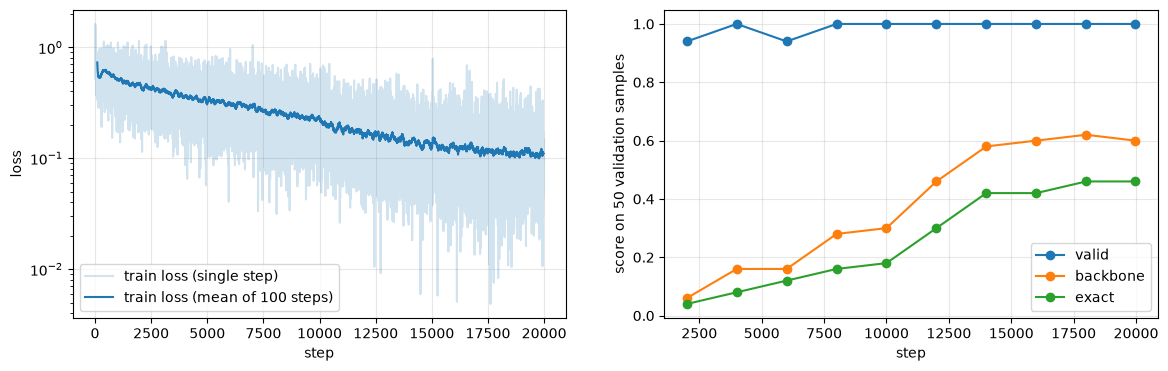

In [10]:
import matplotlib.pyplot as plt

steps = np.array([r["step"] for r in log])
losses = np.array([r["loss"] for r in log])
window = min(100, len(losses))
smooth = np.convolve(losses, np.ones(window) / window, mode="valid")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(steps, losses, color="tab:blue", alpha=0.2, label="train loss (single step)")
ax1.plot(steps[window - 1:], smooth, color="tab:blue", label=f"train loss (mean of {window} steps)")
ax1.set_xlabel("step")
ax1.set_ylabel("loss")
ax1.set_yscale("log")
ax1.legend()
ax1.grid(alpha=0.3)

evals = pl.DataFrame(eval_log)
for metric in ["valid", "backbone", "exact"]:
    ax2.plot(evals["step"], evals[metric], marker="o", label=metric)
ax2.set_xlabel("step")
ax2.set_ylabel(f"score on {len(eval_records)} validation samples")
ax2.legend()
ax2.grid(alpha=0.3)

## vs base model

In [11]:
final_records = val_records[:100]
lora_results = evaluate(final_records)
with model.disable_adapter():  # adapters off, the model uses only the base weights
    base_results = evaluate(final_records)

pl.concat([
    base_results.with_columns(pl.lit("base model").alias("model")),
    lora_results.with_columns(pl.lit("LoRA").alias("model")),
]).select("model", "valid", "backbone", "exact")

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

model,valid,backbone,exact
str,f64,f64,f64
"""base model""",0.38,0.0,0.0
"""LoRA""",1.0,0.53,0.46


## M2S benchmark

In [12]:
from glyph.markush.eval.benchmark_data import materialize_benchmark

eval_jsonl, m2s_root = materialize_benchmark("m2s", Path("data/mini/m2s"))
m2s_items = [json.loads(line) for line in eval_jsonl.read_text().splitlines()]


@torch.no_grad()
def predict_m2s(item):
    image = Image.open(m2s_root / item["image"]).convert("RGB")
    inputs = processor(text=[prompt_text(item["prompt"])], images=[image], return_tensors="pt").to(DEVICE)
    # targets with <stable> text are longer than MolParser ones, so allow more new tokens
    out = base.generate(**inputs, max_new_tokens=768, do_sample=False, eos_token_id=IM_END, pad_token_id=IM_END)
    return processor.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


model.eval()
m2s_predictions = [predict_m2s(item) for item in tqdm(m2s_items)]
(OUT_DIR / "m2s_predictions.json").write_text(json.dumps(m2s_predictions))

  0%|          | 0/103 [00:00<?, ?it/s]

29264

In [13]:
# invalid predictions have no stable_* fields, count them as 0
metrics = ["valid_pred", "backbone_inchi_match", "cxsmiles_full_match", "r_full_match", "stable_equality", "markush_full_match"]


def m2s_scores(predictions):
    samples = [grade(p, item["annotation"])["sample"] for item, p in zip(m2s_items, predictions)]
    return pl.DataFrame([{m: float(s.get(m) or 0) for m in metrics} for s in samples]).mean()


old_predictions = json.load(open("data/lora_0.8b_molparser_peft/m2s_predictions.json"))
pl.concat([
    m2s_scores(old_predictions).with_columns(pl.lit("original labels (03)").alias("run")),
    m2s_scores(m2s_predictions).with_columns(pl.lit("normalized labels (05)").alias("run")),
]).select("run", *metrics)

run,valid_pred,backbone_inchi_match,cxsmiles_full_match,r_full_match,stable_equality,markush_full_match
str,f64,f64,f64,f64,f64,f64
"""original labels (03)""",0.970874,0.291262,0.009709,0.038835,0.0,0.0
"""normalized labels (05)""",0.854369,0.262136,0.184466,0.281553,0.0,0.0
